In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             matthews_corrcoef, ConfusionMatrixDisplay)

In [2]:
SEED = 42
df = pd.read_csv("../data/processed/ids_processed.csv")
NON_FEATURES = ["row_id", "source_file", "Label_original", "Class"]

In [3]:
# Stratified sample of 100,000 rows (pipeline check only, not the final test set)
sample, _ = train_test_split(df, train_size=100_000,
                             stratify=df["Label_original"], random_state=SEED)
X = sample.drop(columns=NON_FEATURES)
y = sample["Class"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.30, stratify=sample["Label_original"], random_state=SEED)


=== Decision tree === training time 0.6 s, MCC 0.9975
              precision    recall  f1-score   support

      Normal     0.9999    0.9995    0.9997     26407
 Brute-force     0.9520    0.9917    0.9714       240
        DDoS     0.9997    0.9997    0.9997      3353

    accuracy                         0.9995     30000
   macro avg     0.9839    0.9970    0.9903     30000
weighted avg     0.9995    0.9995    0.9995     30000



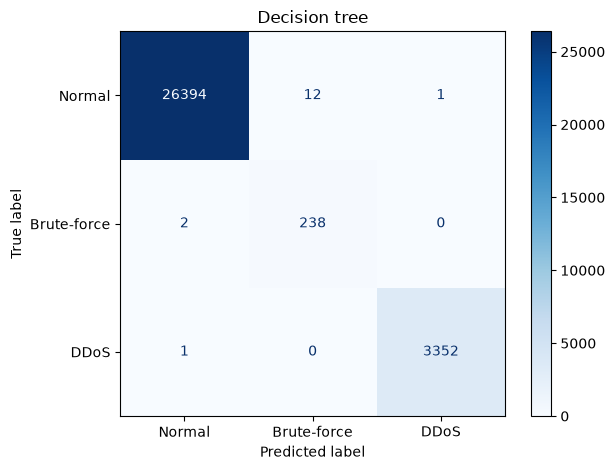


=== Random Forest === training time 1.0 s, MCC 0.9995
              precision    recall  f1-score   support

      Normal     0.9999    1.0000    0.9999     26407
 Brute-force     1.0000    0.9917    0.9958       240
        DDoS     1.0000    0.9997    0.9999      3353

    accuracy                         0.9999     30000
   macro avg     1.0000    0.9971    0.9985     30000
weighted avg     0.9999    0.9999    0.9999     30000



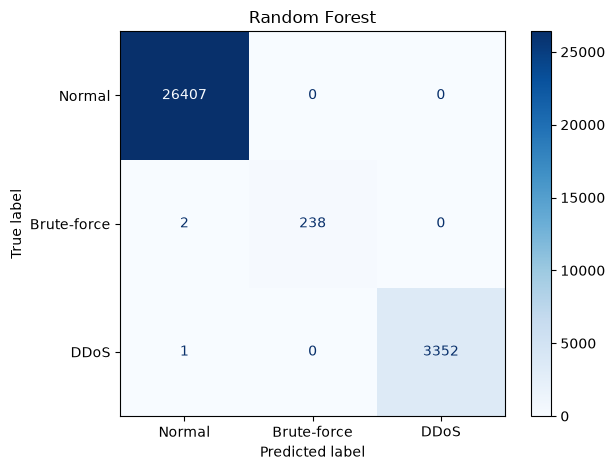

In [4]:
models = {
    "Decision tree": DecisionTreeClassifier(max_depth=10, class_weight="balanced",
                                            random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                            n_jobs=-1, random_state=SEED),
}
labels = ["Normal", "Brute-force", "DDoS"]
for name, model in models.items():
    t0 = time.perf_counter(); model.fit(X_tr, y_tr); fit_s = time.perf_counter() - t0
    pred = model.predict(X_te)
    print(f"\n=== {name} === training time {fit_s:.1f} s, MCC {matthews_corrcoef(y_te, pred):.4f}")
    print(classification_report(y_te, pred, labels=labels, digits=4))   # Table 8
    cm = confusion_matrix(y_te, pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
    plt.title(name); plt.tight_layout()
    plt.savefig(f"../figures/fig6_confusion_{name.replace(' ', '_')}.png", dpi=200); plt.show()